In [1]:
from langgraph.graph import StateGraph, START, MessagesState
from langgraph.checkpoint.memory import InMemorySaver
from dotenv import load_dotenv

from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages.utils import trim_messages,count_tokens_approximately

c:\Users\princ\AppData\Local\Programs\Python\Python310\lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.7.0) or chardet (7.5.1)/charset_normalizer (3.4.7) doesn't match a supported version!
  warnings.warn(
c:\Users\princ\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
load_dotenv()

True

In [3]:
model = ChatGoogleGenerativeAI(model="gemini-2.5-flash-lite")

Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.


In [4]:
MAX_TOKENS = 150

In [6]:
def call_model(state: MessagesState):
    
    # Trim conversation history -> last N messages that fit within the token budget
    messages = trim_messages(
        state["messages"],
        strategy="last",          # last ke n messages rakho baaki jo n ke bahar hain unhe hata do.            
        token_counter=count_tokens_approximately,
        max_tokens=MAX_TOKENS
    )

    print('Current Token Count ->', count_tokens_approximately(messages=messages))

    for message in messages:
        print(message.content)

    response = model.invoke(messages)

    return {"messages": [response]}

In [7]:
builder = StateGraph(MessagesState)
builder.add_node("call_model", call_model)
builder.add_edge(START, "call_model")

In [8]:
checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

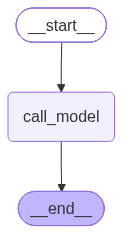

In [9]:
graph

In [10]:
config = {"configurable": {"thread_id": "chat-1"}}

result = graph.invoke(
    {"messages": [{"role": "user", "content": "Hi, my name is Prince."}]},
    config,
)

result["messages"][-1].content

Current Token Count -> 10
Hi, my name is Prince.


"Hello Prince, it's a pleasure to meet you! How can I help you today?"

In [11]:
result = graph.invoke(
    {"messages": [{"role": "user", "content": "I am learning LangGraph."}]},
    config,
)

result["messages"][-1].content

Current Token Count -> 43
Hi, my name is Prince.
Hello Prince, it's a pleasure to meet you! How can I help you today?
I am learning LangGraph.


'That\'s fantastic, Prince! LangGraph is a powerful and exciting library for building complex, multi-agent, and stateful applications with LLMs.\n\n**What are you finding most interesting or challenging about it so far?**\n\nTo help me guide you better, could you tell me a bit about:\n\n*   **Your current level of experience with LangGraph:** Are you just starting, have you built a few simple graphs, or are you diving into more advanced concepts?\n*   **What you\'re hoping to achieve with LangGraph:** Are you building a specific type of application (e.g., a chatbot, a research assistant, a code generation tool)?\n*   **Any specific areas you\'re struggling with or curious about:** For example, are you wondering about:\n    *   Defining nodes and edges?\n    *   Managing state?\n    *   Implementing conditional logic (e.g., `conditional_edge`)?\n    *   Working with different tools or agents?\n    *   Testing and debugging your graphs?\n    *   Specific examples or use cases?\n\nThe mor

In [12]:
result = graph.invoke(
    {"messages": [{"role": "user", "content": "Can you explain short term memory?"}]},
    config,
)

result["messages"][-1].content

Current Token Count -> 13
Can you explain short term memory?


'Short-term memory (STM), also known as **working memory** or **active memory**, is a crucial cognitive system that holds and manipulates information for a brief period. Think of it as the mental scratchpad or a temporary holding area where you keep information you\'re actively using or thinking about right now.\n\nHere\'s a breakdown of its key characteristics and functions:\n\n**Key Characteristics:**\n\n*   **Limited Capacity:** STM can only hold a small amount of information at any given time. The classic estimate is around **7 plus or minus 2 items** (Miller\'s Law), though more recent research suggests it might be closer to **4 chunks** of information. A "chunk" can be a single item (like a letter) or a group of items that are meaningfully related (like a word or a phone number).\n*   **Limited Duration:** Information in STM decays very quickly if it\'s not actively rehearsed or processed. Without conscious effort, it typically lasts for about **15-30 seconds**.\n*   **Active Pro

In [13]:
result = graph.invoke(
    {"messages": [{"role": "user", "content": "What is my name?"}]},
    config,
)

result["messages"][-1].content

Current Token Count -> 8
What is my name?


'I do not know your name. I am a large language model, trained by Google. I do not have access to personal information about you.'

In [14]:
for item in graph.get_state({"configurable": {"thread_id": "chat-1"}}).values['messages']:
    print(item.content)
    print('-'*120)

Hi, my name is Prince.
------------------------------------------------------------------------------------------------------------------------
Hello Prince, it's a pleasure to meet you! How can I help you today?
------------------------------------------------------------------------------------------------------------------------
I am learning LangGraph.
------------------------------------------------------------------------------------------------------------------------
That's fantastic, Prince! LangGraph is a powerful and exciting library for building complex, multi-agent, and stateful applications with LLMs.

**What are you finding most interesting or challenging about it so far?**

To help me guide you better, could you tell me a bit about:

*   **Your current level of experience with LangGraph:** Are you just starting, have you built a few simple graphs, or are you diving into more advanced concepts?
*   **What you're hoping to achieve with LangGraph:** Are you building a spec